## Importación de librerías


In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score, roc_curve
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate, learning_curve, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree

palette = sns.color_palette("deep", 3)
sns.set_theme(style="whitegrid", palette=palette)
class_palette = dict(zip([1, 2, 3], palette))
survival_palette = {0: palette[0], 1: palette[1]}
model_palette = dict(zip(["Inicial", "Sin atípicos", "Optimizado sin atípicos"], palette))
heatmap_cmap = sns.light_palette(palette[0], as_cmap=True)
correlation_cmap = sns.blend_palette([palette[1], "white", palette[0]], as_cmap=True)


## Carga de datos


In [2]:
raiz = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
df = pd.read_csv(raiz / "data" / "titanic.csv")
df.head()


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


## Exploración inicial


In [3]:
df.shape


(891, 15)

In [4]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    str    
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    str    
 8   class        891 non-null    str    
 9   who          891 non-null    str    
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    str    
 12  embark_town  889 non-null    str    
 13  alive        891 non-null    str    
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), str(7)
memory usage: 92.4 KB


In [5]:
df.describe()


,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


## Valores faltantes


In [6]:
pd.DataFrame({
    "nulos": df.isna().sum(),
    "porcentaje": df.isna().mean() * 100
}).sort_values("nulos", ascending=False)


,nulos,porcentaje
deck,688,77.216611
age,177,19.865320
embarked,2,0.224467
embark_town,2,0.224467
sex,0,0.000000
pclass,0,0.000000
survived,0,0.000000
fare,0,0.000000
parch,0,0.000000
sibsp,0,0.000000


## Detección de duplicados


In [7]:
df.duplicated().sum()


np.int64(107)

## Distribución de la supervivencia


In [8]:
df["survived"].value_counts(normalize=True) # "normalize" retorona la proporción de cada clase en lugar del conteo


survived
0    0.616162
1    0.383838
Name: proportion, dtype: float64

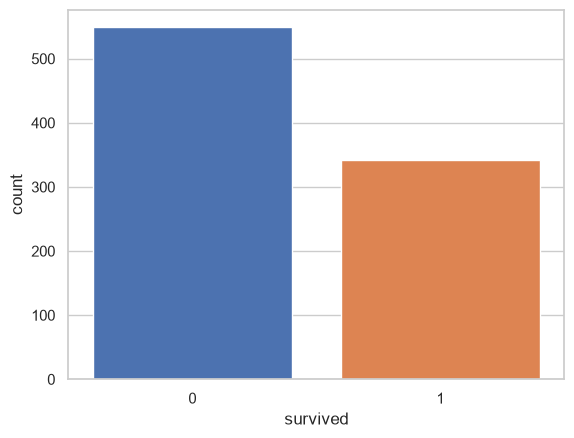

In [9]:
sns.countplot(data=df, x="survived", hue="survived", palette=survival_palette, saturation=1, legend=False)
plt.show()


## Variables categóricas y supervivencia


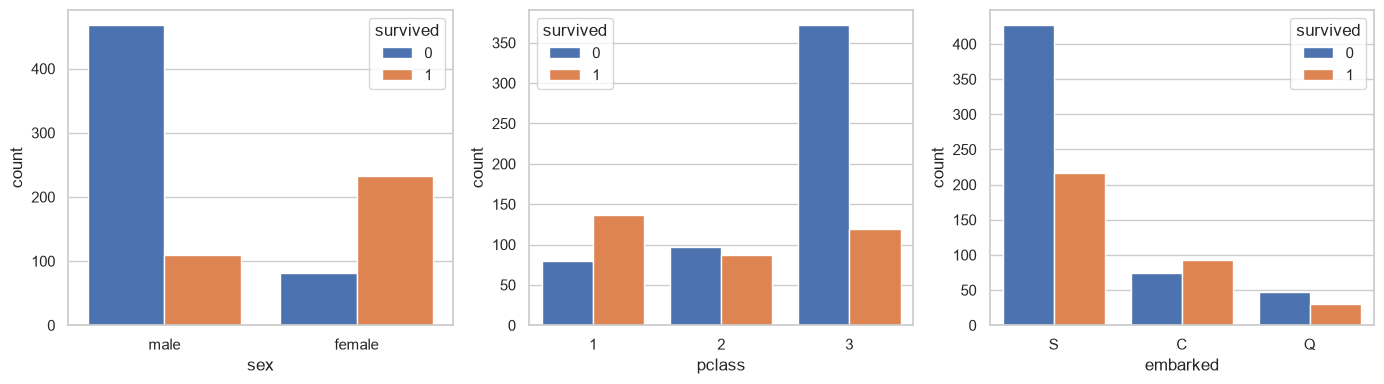

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for column, ax in zip(["sex", "pclass", "embarked"], axes):
    sns.countplot(data=df, x=column, hue="survived", palette=survival_palette, saturation=1, ax=ax)
plt.tight_layout()
plt.show()


## Distribución de variables numéricas


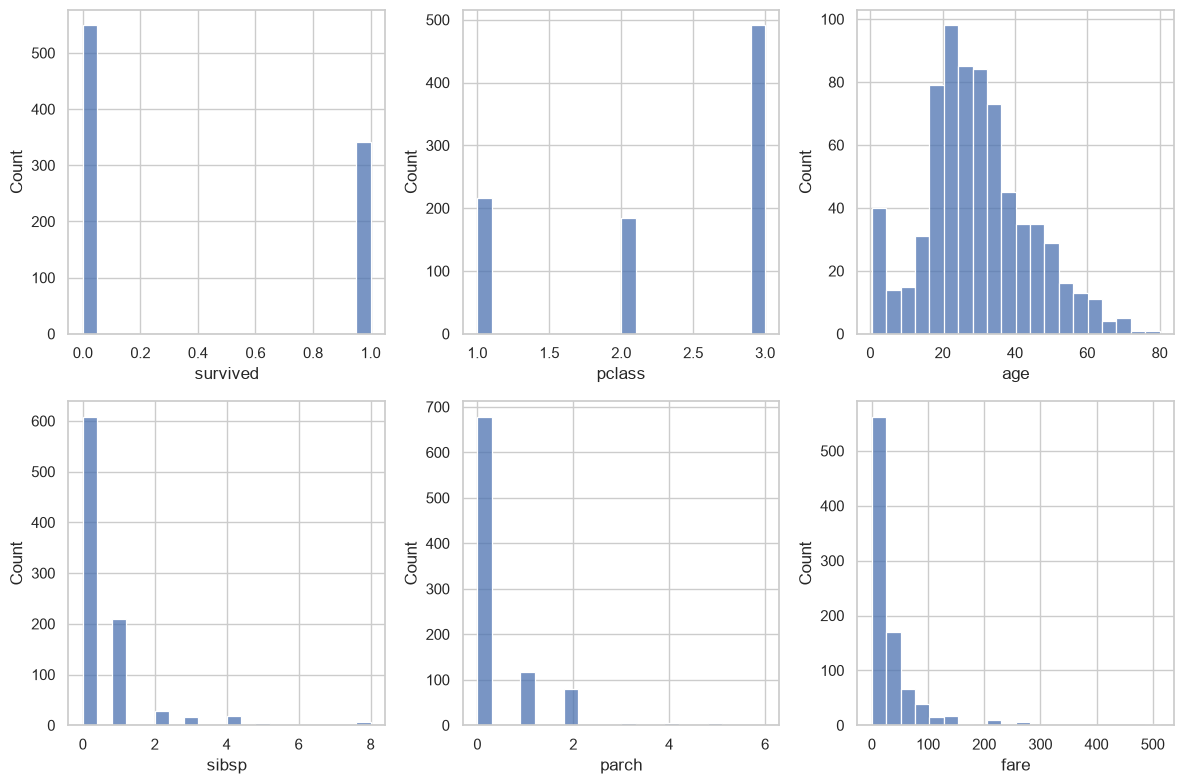

In [11]:
df_numeric = df.select_dtypes(include="number")
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for column, ax in zip(df_numeric.columns, axes.flat):
    sns.histplot(data=df_numeric, x=column, bins=20, color=palette[0], ax=ax)
plt.tight_layout()
plt.show()


## Relaciones entre variables


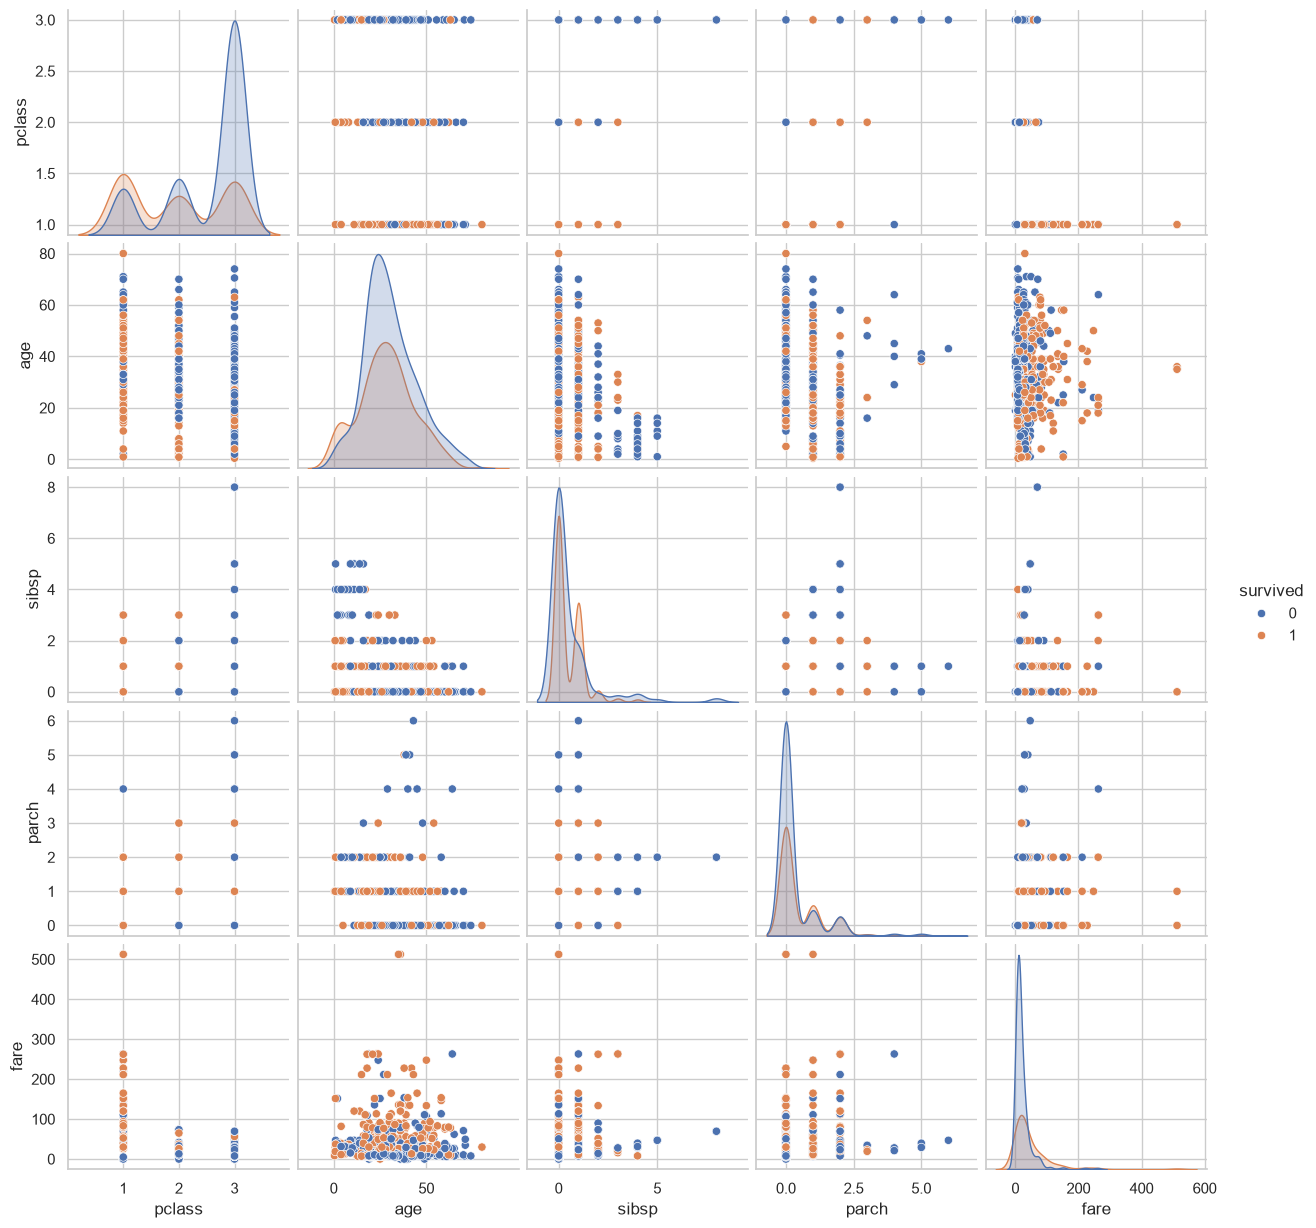

In [12]:
sns.pairplot(df_numeric, hue="survived", diag_kind="kde", palette=survival_palette)
plt.show()


## Matriz de correlación


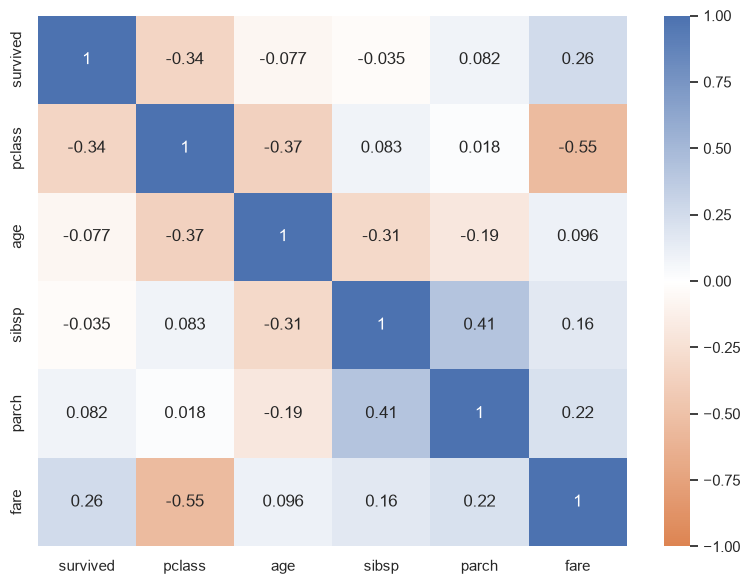

In [13]:
plt.figure(figsize=(8, 6))
sns.heatmap(df_numeric.corr(), annot=True, cmap=correlation_cmap, center=0, vmin=-1, vmax=1)
plt.tight_layout()
plt.show()


## Detección de valores atípicos de fare por pclass


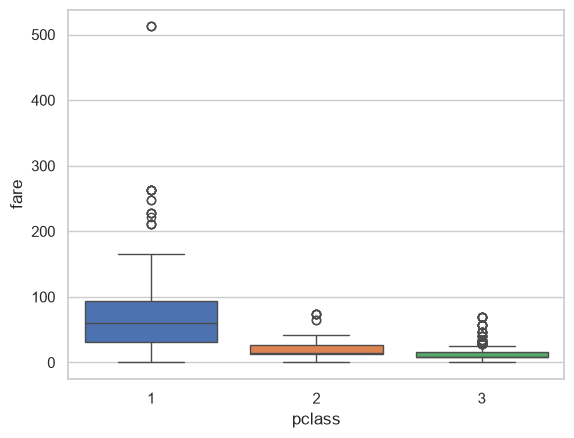

In [14]:
sns.boxplot(data=df, x="pclass", y="fare", hue="pclass", palette=class_palette, saturation=1, legend=False)
plt.show()


In [15]:
fare_groups = df.groupby("pclass")["fare"]
q1 = fare_groups.transform("quantile", q=0.25)
q3 = fare_groups.transform("quantile", q=0.75)
iqr = q3 - q1
outliers = (df["fare"] < q1 - 1.5 * iqr) | (df["fare"] > q3 + 1.5 * iqr)
outliers.groupby(df["pclass"]).sum().rename("tarifas_atipicas")


pclass
1    20
2     7
3    52
Name: tarifas_atipicas, dtype: int64

## Selección de variables predictoras y objetivo


In [16]:
numeric_features = ["age", "fare"]
categorical_features = ["sex", "embarked", "pclass", "sibsp", "parch"]

X = df[numeric_features + categorical_features]
y = df["survived"]


## División en entrenamiento y prueba


In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
X_train.shape, X_test.shape


((712, 7), (179, 7))

## Eliminación de tarifas atípicas por pclass: IQR de entrenamiento


In [18]:
def fare_inliers(data):
    fare = data.groupby("pclass")["fare"]
    q1 = fare.transform("quantile", q=0.25)
    q3 = fare.transform("quantile", q=0.75)
    iqr = q3 - q1
    return data["fare"].between(q1 - 1.5 * iqr, q3 + 1.5 * iqr) | data["fare"].isna()

keep = fare_inliers(X_train)
X_train_clean = X_train.loc[keep].copy()
y_train_clean = y_train.loc[keep].copy()

print(f"Antes: {len(X_train)} | Después: {len(X_train_clean)} | Eliminados: {(~keep).sum()}")


Antes: 712 | Después: 647 | Eliminados: 65


## Fare antes y después de eliminar atípicos de entrenamiento


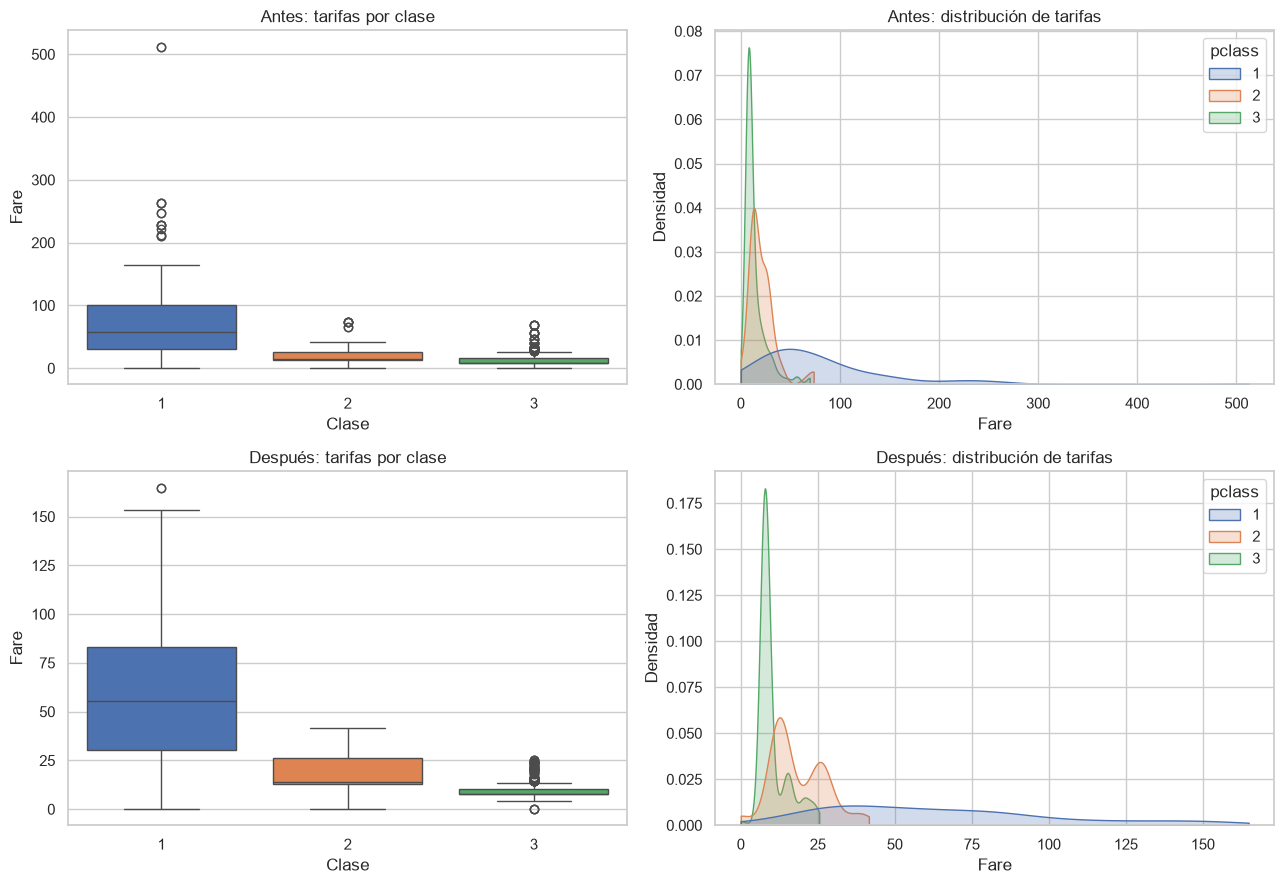

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharex=False, sharey=False)
for row, (title, data) in enumerate([("Antes", X_train), ("Después", X_train_clean)]):
    sns.boxplot(
        data=data, x="pclass", y="fare", hue="pclass", palette=class_palette,
        saturation=1, legend=False, ax=axes[row, 0]
    )
    sns.kdeplot(
        data=data, x="fare", hue="pclass", palette=class_palette,
        fill=True, common_norm=False, alpha=0.25, cut=0, ax=axes[row, 1]
    )
    axes[row, 0].set_title(f"{title}: tarifas por clase")
    axes[row, 0].set_xlabel("Clase")
    axes[row, 0].set_ylabel("Fare")
    axes[row, 1].set_title(f"{title}: distribución de tarifas")
    axes[row, 1].set_xlabel("Fare")
    axes[row, 1].set_ylabel("Densidad")
plt.tight_layout()
plt.show()


## Imputación y codificación de variables


In [20]:
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median"), numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])


## Árbol inicial con y sin eliminación de atípicos


In [21]:
baseline_model = Pipeline([
    ("preprocessor", preprocessor),
    ("tree", DecisionTreeClassifier(random_state=42))
])
baseline_model.fit(X_train, y_train) # modelo control - datos originales con outliers
clean_model = clone(baseline_model).fit(X_train_clean, y_train_clean) # modelo sin atípicos


## Modelo optimizado


In [22]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
folds = list(cv.split(X_train, y_train))
clean_folds = []

for train_idx, valid_idx in folds:
    keep_fold = fare_inliers(X_train.iloc[train_idx]).to_numpy()
    clean_folds.append((train_idx[keep_fold], valid_idx))


## GridSearchCV: selección por AUC con 5 folds


In [23]:
param_grid = {
    "tree__criterion": ["gini", "entropy"],
    "tree__max_depth": [3, 4, 5, 6],
    "tree__min_samples_split": [2, 10],
    "tree__min_samples_leaf": [1, 3, 5]
}

scoring = {"accuracy": "accuracy", "auc": "roc_auc"}
grid_search = GridSearchCV(
    baseline_model, param_grid, cv=clean_folds, scoring=scoring,
    refit=False, error_score="raise"
)
grid_search.fit(X_train, y_train)


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'tree__criterion': ['gini', 'entropy'], 'tree__max_depth': [3, 4, ...], 'tree__min_samples_leaf': [1, 3, ...], 'tree__min_samples_split': [2, 10]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'accuracy': 'accuracy', 'auc': 'roc_auc'}"
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",False
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.","[(array([ 1, ...07, 710, 711]), ...), (array([ 1, ...02, 703, 705]), ...), ...]"
,"error_score error_score: 'raise' or numeric, default=np.nanValue to assign to the score if an error occurs in estimator fitting.If set to 'raise', t

In [24]:
results = pd.DataFrame(grid_search.cv_results_)
best_index = results["mean_test_auc"].idxmax()
best_params = results.loc[best_index, "params"]
model = clone(baseline_model).set_params(**best_params)
model.fit(X_train_clean, y_train_clean)
best_params


{'tree__criterion': 'entropy',
 'tree__max_depth': 3,
 'tree__min_samples_leaf': 3,
 'tree__min_samples_split': 2}

In [25]:
results[[
    "mean_test_auc", "std_test_auc", "mean_test_accuracy", "params"
]].sort_values("mean_test_auc", ascending=False).head()


,mean_test_auc,std_test_auc,mean_test_accuracy,params
27,0.852990,0.024988,0.80197,"{'tree__criterion': 'entropy', 'tree__max_dept..."
26,0.852990,0.024988,0.80197,"{'tree__criterion': 'entropy', 'tree__max_dept..."
29,0.852759,0.024876,0.80197,"{'tree__criterion': 'entropy', 'tree__max_dept..."
28,0.852759,0.024876,0.80197,"{'tree__criterion': 'entropy', 'tree__max_dept..."
5,0.852001,0.024940,0.80197,"{'tree__criterion': 'gini', 'tree__max_depth':..."


## AUC y accuracy por fold: el optimizado usa los folds de selección del grid


In [26]:
fold_results = []
for name, splits in [("Inicial", folds), ("Sin atípicos", clean_folds)]:
    scores = cross_validate(
        baseline_model, X_train, y_train, cv=splits,
        scoring=scoring, error_score="raise"
    )
    for fold in range(5):
        fold_results.append({
            "modelo": name, "fold": fold + 1,
            "auc": scores["test_auc"][fold],
            "accuracy": scores["test_accuracy"][fold]
        })

for fold in range(5):
    fold_results.append({
        "modelo": "Optimizado sin atípicos", "fold": fold + 1,
        "auc": results.loc[best_index, f"split{fold}_test_auc"],
        "accuracy": results.loc[best_index, f"split{fold}_test_accuracy"]
    })

cv_results = pd.DataFrame(fold_results)
cv_pivot = cv_results.pivot(index="fold", columns="modelo", values=["auc", "accuracy"])
cv_pivot


auc                                       accuracy  \
modelo   Inicial Optimizado sin atípicos Sin atípicos   Inicial   
fold                                                              
1       0.755165                0.852996     0.727479  0.769231   
2       0.736777                0.832335     0.751550  0.762238   
3       0.765831                0.898537     0.738558  0.774648   
4       0.797980                0.853009     0.780724  0.795775   
5       0.779040                0.828072     0.768729  0.795775   

                                             
modelo Optimizado sin atípicos Sin atípicos  
fold                                         
1                     0.811189     0.727273  
2                     0.790210     0.762238  
3                     0.802817     0.746479  
4                     0.823944     0.781690  
5                     0.781690     0.774648

In [27]:
comparison_cv = cv_results.groupby("modelo")[["auc", "accuracy"]].agg(["mean", "std"])
comparison_cv


auc            accuracy          
                             mean       std      mean       std
modelo                                                         
Inicial                  0.766959  0.023236  0.779533  0.015465
Optimizado sin atípicos  0.852990  0.027938  0.801970  0.016719
Sin atípicos             0.753408  0.021663  0.758465  0.021978

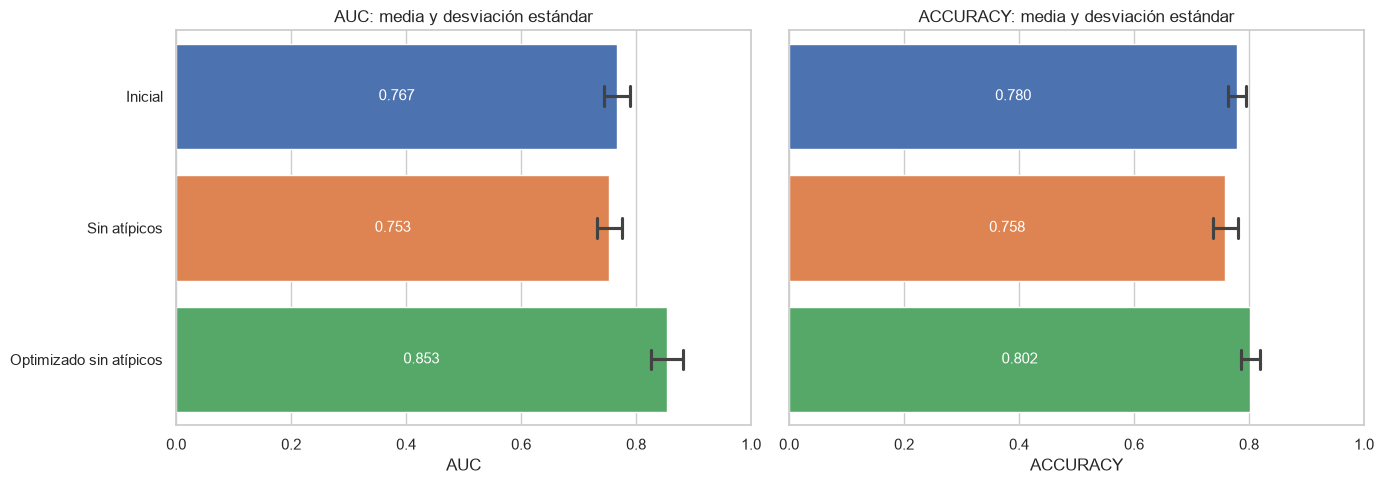

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for metric, ax in zip(["auc", "accuracy"], axes):
    sns.barplot(
        data=cv_results, x=metric, y="modelo", hue="modelo", palette=model_palette, saturation=1,
        errorbar="sd", capsize=0.15, legend=False, ax=ax
    )
    ax.set_xlim(0, 1)
    ax.set_xlabel(metric.upper())
    ax.set_ylabel("")
    ax.set_title(f"{metric.upper()}: media y desviación estándar")
    for bars in ax.containers:
        ax.bar_label(bars, fmt="%.3f", label_type="center", color="white", fontsize=11)
plt.tight_layout()
plt.show()


## Curvas de aprendizaje del árbol seleccionado: accuracy y AUC


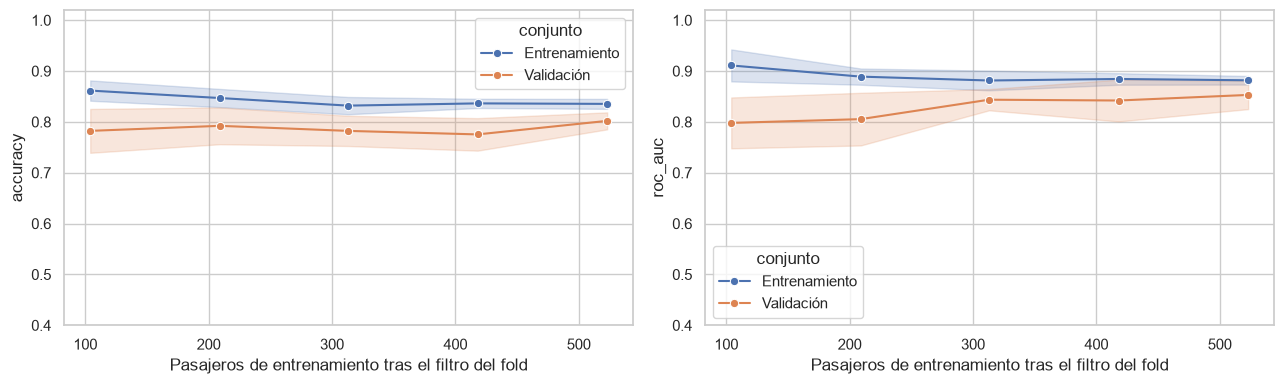

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
learning_results = {}

for metric, ax in zip(["accuracy", "roc_auc"], axes):
    sizes, train_scores, valid_scores = learning_curve(
        model, X_train, y_train, cv=clean_folds,
        train_sizes=[0.2, 0.4, 0.6, 0.8, 1.0],
        scoring=metric, shuffle=True, random_state=42, error_score="raise"
    )
    learning_results[metric] = (sizes, train_scores, valid_scores)
    curves = []
    for label, scores in [("Entrenamiento", train_scores), ("Validación", valid_scores)]:
        values = pd.DataFrame(scores, index=sizes).rename_axis("pasajeros").reset_index()
        values = values.melt(id_vars="pasajeros", var_name="fold", value_name="puntuación")
        values["conjunto"] = label
        curves.append(values)
    sns.lineplot(
        data=pd.concat(curves), x="pasajeros", y="puntuación", hue="conjunto",
        palette={"Entrenamiento": palette[0], "Validación": palette[1]},
        errorbar="sd", marker="o", ax=ax
    )
    ax.set_xlabel("Pasajeros de entrenamiento tras el filtro del fold")
    ax.set_ylabel(metric)
    ax.set_ylim(0.4, 1.02)

plt.tight_layout()
plt.show()


## Evaluación final en el conjunto de prueba


In [30]:
models = {
    "Inicial": baseline_model,
    "Sin atípicos": clean_model,
    "Optimizado sin atípicos": model
}

test_results = []
for name, estimator in models.items():
    predictions = estimator.predict(X_test)
    probabilities = estimator.predict_proba(X_test)[:, 1]
    test_results.append({
        "modelo": name,
        "accuracy_prueba": accuracy_score(y_test, predictions),
        "auc_prueba": roc_auc_score(y_test, probabilities)
    })

comparison_test = pd.DataFrame(test_results).set_index("modelo")
y_pred = model.predict(X_test)
comparison_test


,accuracy_prueba,auc_prueba
modelo,,
Inicial,0.798883,0.775955
Sin atípicos,0.765363,0.748419
Optimizado sin atípicos,0.798883,0.840975


## Comparación de curvas ROC en prueba sin eliminar pasajeros


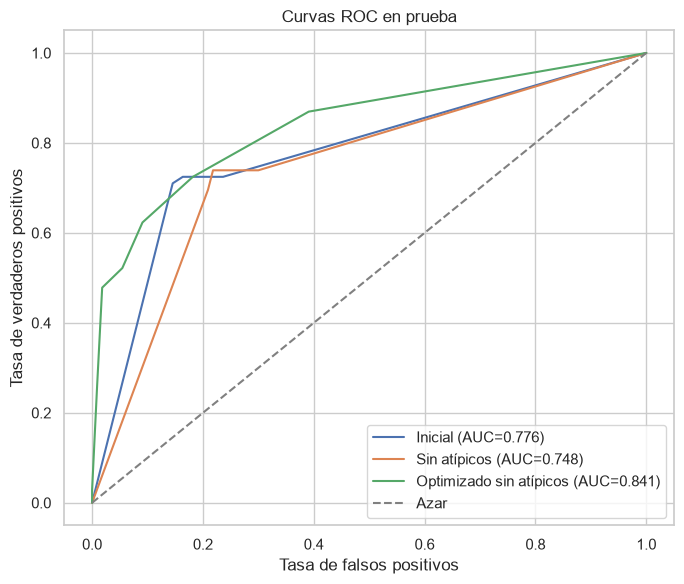

In [31]:
fig, ax = plt.subplots(figsize=(7, 6))
for name, estimator in models.items():
    probabilities = estimator.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    auc = roc_auc_score(y_test, probabilities)
    sns.lineplot(
        x=fpr, y=tpr, estimator=None, sort=False, errorbar=None,
        label=f"{name} (AUC={auc:.3f})", color=model_palette[name], ax=ax
    )
sns.lineplot(x=[0, 1], y=[0, 1], color="gray", linestyle="--", label="Azar", ax=ax)
ax.set_xlabel("Tasa de falsos positivos")
ax.set_ylabel("Tasa de verdaderos positivos")
ax.set_title("Curvas ROC en prueba")
plt.tight_layout()
plt.show()


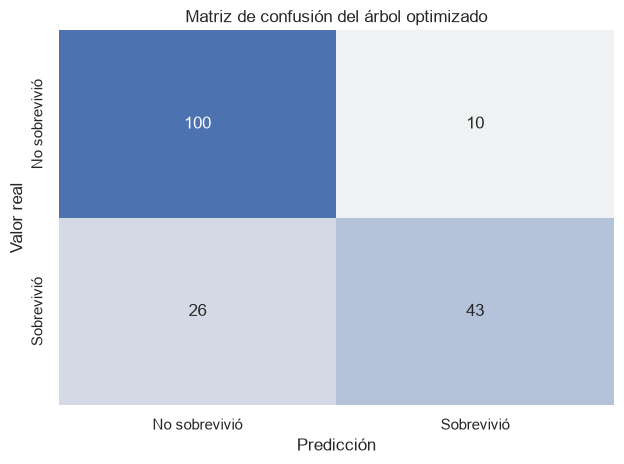

In [32]:
sns.heatmap(
    confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap=heatmap_cmap, cbar=False,
    xticklabels=["No sobrevivió", "Sobrevivió"],
    yticklabels=["No sobrevivió", "Sobrevivió"]
)
plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.title("Matriz de confusión del árbol optimizado")
plt.tight_layout()
plt.show()


## Importancia de las variables


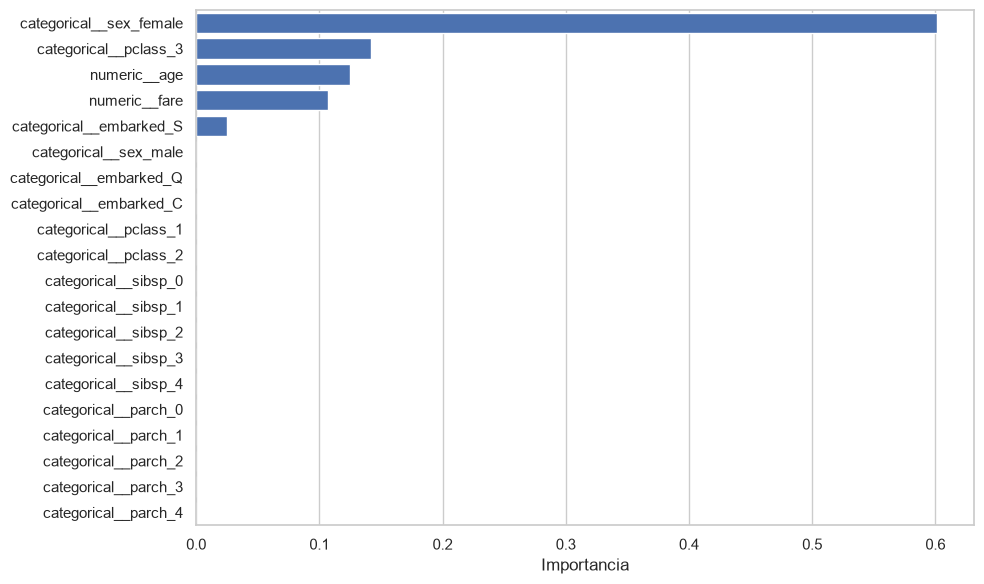

In [33]:
feature_names = model.named_steps["preprocessor"].get_feature_names_out()
importances = pd.Series(model.named_steps["tree"].feature_importances_, index=feature_names)
importance_table = importances.rename_axis("variable").reset_index(name="importancia")

plt.figure(figsize=(10, 6))
sns.barplot(
    data=importance_table.sort_values("importancia", ascending=False),
    x="importancia", y="variable", color=palette[0], saturation=1
)
plt.xlabel("Importancia")
plt.ylabel("")
plt.tight_layout()
plt.show()


## Modelo reducido con las cinco características seleccionadas


In [34]:
selected_numeric = ["age", "fare"]
selected_binary = ["sex_female", "pclass_3", "embarked_S"]

X_selected = X[selected_numeric].copy()
X_selected["sex_female"] = X["sex"].map({"female": 1, "male": 0})
X_selected["pclass_3"] = X["pclass"].eq(3).astype(float).where(X["pclass"].notna())
X_selected["embarked_S"] = X["embarked"].eq("S").astype(float).where(X["embarked"].notna())

X_train_selected = X_selected.loc[X_train.index]
X_test_selected = X_selected.loc[X_test.index]
X_train_selected_clean = X_selected.loc[X_train_clean.index]
X_train_selected.head()


,age,fare,sex_female,pclass_3,embarked_S
692,NaN,56.4958,0,1.0,1.0
481,NaN,0.0000,0,0.0,1.0
527,NaN,221.7792,0,0.0,1.0
855,18.0,9.3500,1,1.0,1.0
801,31.0,26.2500,1,0.0,1.0


In [35]:
selected_preprocessor = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median"), selected_numeric),
    ("binary", SimpleImputer(strategy="most_frequent"), selected_binary)
])

selected_pipeline = Pipeline([
    ("preprocessor", selected_preprocessor),
    ("tree", DecisionTreeClassifier(random_state=42))
])


## Optimización del modelo reducido: mismo grid y mismos 5 folds


In [36]:
selected_search = GridSearchCV(
    selected_pipeline, param_grid, cv=clean_folds, scoring=scoring,
    refit=False, error_score="raise"
)
selected_search.fit(X_train_selected, y_train)
selected_results = pd.DataFrame(selected_search.cv_results_)
selected_best_index = selected_results["mean_test_auc"].idxmax()
selected_best_params = selected_results.loc[selected_best_index, "params"]

selected_model = clone(selected_pipeline).set_params(**selected_best_params)
selected_model.fit(X_train_selected_clean, y_train_clean)
selected_best_params


{'tree__criterion': 'gini',
 'tree__max_depth': 3,
 'tree__min_samples_leaf': 3,
 'tree__min_samples_split': 2}

## Reportes de clasificación y AUC: todas frente a seleccionadas


In [37]:
feature_models = {
    "Todas": (model, X_test),
    "Seleccionadas": (selected_model, X_test_selected)
}

for name, (estimator, test_data) in feature_models.items():
    predictions = estimator.predict(test_data)
    probabilities = estimator.predict_proba(test_data)[:, 1]
    print(name)
    print(classification_report(
        y_test, predictions,
        target_names=["No sobrevivió", "Sobrevivió"], zero_division=0
    ))
    print(f"AUC: {roc_auc_score(y_test, probabilities):.4f}\n")


Todas
               precision    recall  f1-score   support

No sobrevivió       0.79      0.91      0.85       110
   Sobrevivió       0.81      0.62      0.70        69

     accuracy                           0.80       179
    macro avg       0.80      0.77      0.78       179
 weighted avg       0.80      0.80      0.79       179

AUC: 0.8410

Seleccionadas
               precision    recall  f1-score   support

No sobrevivió       0.79      0.91      0.85       110
   Sobrevivió       0.81      0.62      0.70        69

     accuracy                           0.80       179
    macro avg       0.80      0.77      0.78       179
 weighted avg       0.80      0.80      0.79       179

AUC: 0.8410



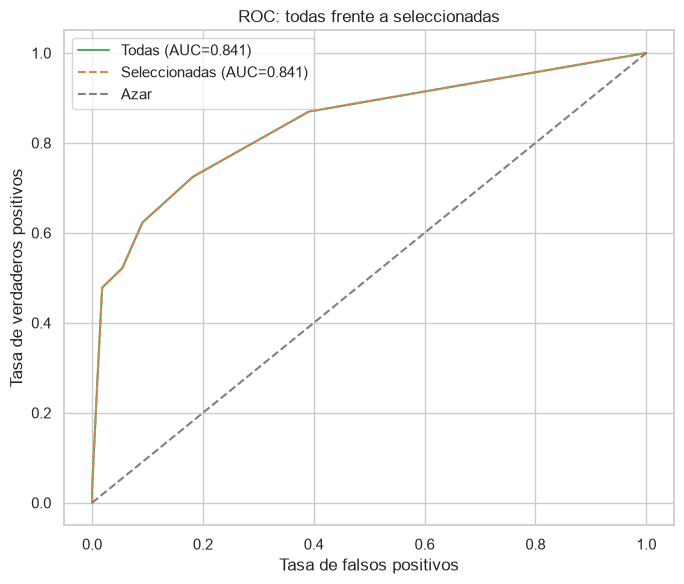

In [38]:
fig, ax = plt.subplots(figsize=(7, 6))
for name, (estimator, test_data) in feature_models.items():
    probabilities = estimator.predict_proba(test_data)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    auc = roc_auc_score(y_test, probabilities)
    sns.lineplot(
        x=fpr, y=tpr, estimator=None, sort=False, errorbar=None,
        label=f"{name} (AUC={auc:.3f})",
        color=palette[2] if name == "Todas" else palette[1],
        linestyle="--" if name == "Seleccionadas" else "-", ax=ax
    )
sns.lineplot(x=[0, 1], y=[0, 1], color="gray", linestyle="--", label="Azar", ax=ax)
ax.set_xlabel("Tasa de falsos positivos")
ax.set_ylabel("Tasa de verdaderos positivos")
ax.set_title("ROC: todas frente a seleccionadas")
plt.tight_layout()
plt.show()


## Visualización del árbol optimizado con todas las características


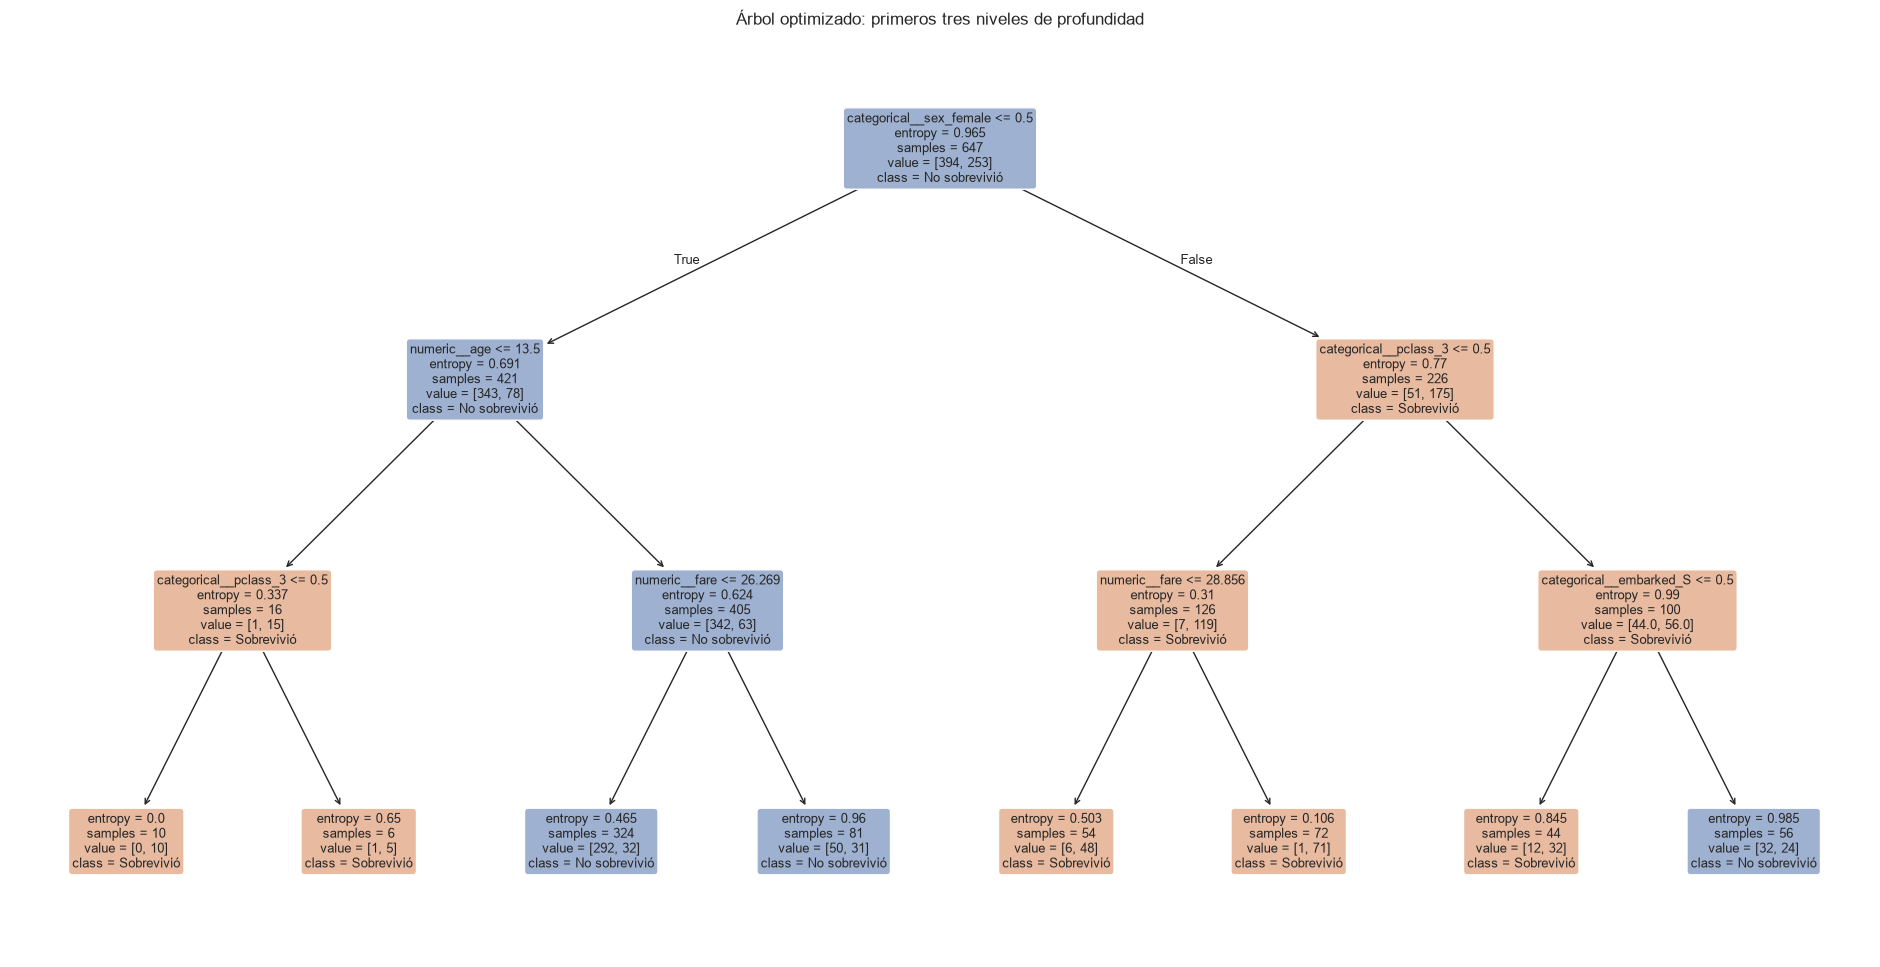

In [39]:
plt.figure(figsize=(24, 12))
nodes = plot_tree(
    model.named_steps["tree"],
    feature_names=feature_names,
    class_names=["No sobrevivió", "Sobrevivió"],
    max_depth=3,
    filled=False,
    rounded=True,
    fontsize=9
)
for node in nodes:
    color = palette[1] if "class = Sobrevivió" in node.get_text() else palette[0]
    if node.get_bbox_patch() is not None:
        node.get_bbox_patch().set_facecolor(sns.light_palette(color, n_colors=3)[1])
plt.title("Árbol optimizado: primeros tres niveles de profundidad")
plt.show()
